# COST 与连通分量：论文怎样选择单线程基线？

**正文先回答论文的问题：在相同的连通分量任务上，分布式系统需要多少资源才能超过实现得当的单线程程序？**

阅读路线：定义任务 → 两种算法及其代码 → 论文表 5 的算法比较 → 论文图 6 的并行并查集 COST。

正文中的时间与核数均来自论文。内嵌 Python/Numba 代码是按作者实现编写的教学移植，便于阅读，不用于生成论文数字。原文使用的真实图为 Twitter 与 uk-2007-05。

**What's more 附录**才是本项目额外设计的内容：小图演示、forward/reverse 链、随机捷径图、同步并行标签传播及本机结果。这些用于探索机制，并非原论文的实验设计。

来源：[COST 原论文](https://www.usenix.org/system/files/conference/hotos15/hotos15-paper-mcsherry.pdf)，第 2.2、3.2、4.2 节；[作者实现核对](author_sources.md)；[中文译文](cost-paper-zh.md)。


In [1]:
import os
for key in ('OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','VECLIB_MAXIMUM_THREADS'):
    os.environ[key]='1'
os.environ.setdefault('MPLCONFIGDIR','/tmp/cost-pagerank-mpl')
import json,platform,time
from concurrent.futures import ThreadPoolExecutor
from numba import njit
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
if 'show' not in globals(): show=plt.show
print(platform.platform())

macOS-26.6.1-arm64-arm-64bit-Mach-O


## 1. 任务：求出无向图的连通分量

沿着图中的边能相互到达的节点，属于同一个连通分量。算法接收节点和边，求出这个分组；并不预先知道分组。

论文先使用标签传播，再用并查集完成同一个任务。二者维护的状态不同：标签传播反复更新节点标签，并查集维护父指针森林和树的 rank。

本 notebook 的教学移植统一输出每个节点所属分量的最小节点编号，方便逐节点检查结果。这项输出规范与作者 CLI 最后输出非根节点数有所区别，导出过程也会影响本地计时。所有自造图和运行示例放在附录。


## 2. 标签传播：把较小编号沿边传下去

先直接写出算法，后面的例子执行的就是这个单元定义的函数。`src[i], dst[i]` 表示一条无向边，`label[v]` 是节点 v 当前知道的最小标签。

1. 每个节点先认为自己单独成组：`label = [0,1,2,...]`。
2. 扫描一条边，两端互通信息，都取两端标签的较小值。
3. 一整轮有变化，就再扫描；一整轮没有变化，停止。

标签只会下降，且只能取有限个节点编号，因此最终停止。停止时每条边的两端标签相同；同一连通分量沿路径标签都相同，最后得到该分量的最小节点编号。孤立节点一直保留自己的编号。

`@njit` 将下面的循环编译成本机代码，算法仍然完全写在这里。`scans` 统计完整扫边次数，包含最后一次无变化的确认轮；第三个返回值是总边访问次数。


In [2]:
@njit
def label_propagation(src, dst, n):
    """Paper's in-place (asynchronous) full scans until no label changes."""
    label = np.arange(n, dtype=np.int64)
    scans = 0
    changed = True
    while changed:
        changed = False
        scans += 1
        for i in range(len(src)):
            u, v = src[i], dst[i]
            if label[u] != label[v]:
                value = min(label[u], label[v])
                label[u], label[v] = value, value
                changed = True
    return label, scans, scans * len(src)

## 3. 并查集：记录集合关系，避免反复传播标签

并查集维护两份数组：

- `root[v]` 是节点 v 的父节点；`root[v] == v` 表示它是树根，也就是一个集合的代表。
- `rank[v]` 是合并时维护的树高度指标，和 PageRank 的排名值无关。两棵同 rank 的树合并时，新根的 rank 加一；否则把较矮的树接到较高的树下。

每条边 `(u,v)` 只处理一次：沿父指针找到 u、v 的根，根不同就连接两个集合。根相同说明已经连通，无需操作。后面的边使集合变大时，原有成员通过父指针自然属于同一个集合，无需重新扫描之前的边。

集合的代表根由合并过程决定。**代表节点不一定是分量最小编号。** 因此函数的后半段遍历节点，先找各自的根，再计算每棵树最小编号，输出与标签传播相同格式的标签。

下面保留作者的“按 rank 合并、不做路径压缩”版本。`steps` 统计沿父指针走了多少步，包括导出标签阶段；它说明一次扫边之外仍有查根工作。


In [3]:
@njit
def union_find(src, dst, n):
    """Weighted union by rank, no path compression, as in the paper.

    Canonical per-vertex labels are included in runtime, unlike original count-only CLI.
    """
    root = np.arange(n, dtype=np.int64)
    rank = np.zeros(n, dtype=np.uint8)
    steps = 0
    for i in range(len(src)):
        x, y = src[i], dst[i]
        while x != root[x]:
            x = root[x]; steps += 1
        while y != root[y]:
            y = root[y]; steps += 1
        if x != y:
            if rank[x] < rank[y]: root[x] = y
            elif rank[x] > rank[y]: root[y] = x
            else:
                root[y] = x
                rank[x] += 1
    labels = np.empty(n, dtype=np.int64)
    minimum = np.full(n, n, dtype=np.int64)
    for i in range(n):
        r = i
        while r != root[r]:
            r = root[r]; steps += 1
        labels[i] = r
        minimum[r] = min(minimum[r], i)
    for i in range(n): labels[i] = minimum[labels[i]]
    return labels, 1, len(src), steps

### 3.1 与论文和保存的 benchmark 对齐

作者 `label_prop.rs` 用标签总和不再下降判断停止；这里用 `changed` 判断本轮有没有更新。作者 `union_find.rs` 按 rank 合并，不含路径压缩。

本 notebook 的两个函数与 `paper_algorithms.py` 的对应算法体一致，直接定义在上面的代码单元中；模块用于独立 benchmark 脚本复用。两者都用 Numba 编译。Notebook 中不启用磁盘 JIT 缓存，以兼容交互执行；首次编译仍应在计时前完成。

我们的父指针和标签是 int64，作者使用 u32；作者 CLI 输出非根节点数，这里导出每个节点的规范化标签，并将导出时间计入基准。详情见 [实现核对](author_sources.md)。


## 4. 论文的比较：先比较实现，再换算法（表 3、表 5）

论文第 2.2 节先比较标签传播：分布式系统的已发表测量，与作者读取 SSD 的单线程实现相比如何？第 3.2 节再引入单线程并查集。表 5 将关键数字汇总如下：

| 实现 | 核数 | Twitter | uk-2007-05 |
|---|---:|---:|---:|
| GraphLab 标签传播 | 128 | 242 s | 714 s |
| GraphX 标签传播 | 128 | 251 s | 800 s |
| 单线程标签传播（SSD） | 1 | 153 s | 417 s |
| 单线程并查集（SSD） | 1 | **15 s** | **30 s** |

**第一层比较：** 单线程标签传播已经比表中的分布式标签传播更快。**第二层比较：** 单线程再换成并查集，时间从 153 s 降到 15 s、从 417 s 降到 30 s。并查集只需扫描边一遍，同时进行查根和合并；标签传播要反复传播直到稳定。

论文因此要求：评价连通分量系统时，要面对完成同一任务的有效替代算法。只展示某种算法随资源增加而变快，会漏掉更低工作量的方案。

这是作者测量与已有系统发表数字的对照，不是本机重跑了所有系统。结论针对论文的数据与实现；附录另行探索其他图上会发生什么。

### 论文怎样讨论顺序？

第 3.1 节明确指出边顺序会影响性能，并说明此前单线程实现按源节点分组枚举边。随后表 4 用 **PageRank** 展示 vertex/Hilbert 布局差异。

连通分量表 5 的重点是标签传播与并查集的算法比较。它没有使用本 notebook 附录的 forward/reverse 链或随机捷径图；也没有提供这些人工顺序下的完整对照矩阵。


## 5. 论文真正的 COST 图：两个并行并查集实现（图 6）

第 4.2 节指出，前述系统发表的连通性结果缺少可用于这一分析的扩展曲线。因此作者改用两个 **Naiad 并行并查集**实现，与单线程并查集比较。

![论文图 6：两个 Naiad 并行并查集与单线程基线](assets/cost-paper/figure-6.png)

读图方法：横轴为核数，纵轴为运行秒数；两条曲线是两个并行实现，水平线是单线程并查集耗时。曲线下降到水平线下方，才表示该配置真正超过单线程基线。

| 并行版本 | 每个节点状态的存储方式 | 论文报告的 COST |
|---|---|---:|
| Naiad UF | 数组 | 10 核 |
| Naiad UF Slow | 哈希表 | 约 100 核 |

两种实现的区别是节点状态的数据结构。较慢版本用哈希表，也获得了不要求节点编号紧凑连续的便利；论文用 COST 将这种便利的性能代价显露出来。

**这里测的是并行并查集，不是并行标签传播。** 本项目没有复现 Naiad 的这两套并行并查集实现。附录中的线程池程序是另写的同步标签传播，不应当用来解释图 6 的实现细节。


## 6. 读完正文应得到什么？

论文的论证顺序是：

1. 同一个连通分量任务，单线程标签传播已具备竞争力。
2. 换成更有效的并查集，单线程基线进一步降低。
3. 并行实现要跨过这个基线，才体现出相对于有效替代方案的性能收益。
4. 数组与哈希表等实现选择，会显著改变跨过基线需要的资源量。

COST 是 **Configuration that Outperforms a Single Thread**。评价重点是超过有效单线程所需的配置；自身加速比只回答同一个实现加资源后快了多少。

正文到这里结束。下面的实验都属于本项目补充，用于理解算法行为和探讨结论的适用条件。


# What's more：本项目补充实验（非论文实验）

这里的图、顺序对照和并行标签传播由本项目设计。使用同样的代码教学移植，但数据与并行模型不同于原论文。

## A. 小图手算：观察标签与父指针怎样变化

构造三个分量 `{0,1,2}`、`{3,4}`、`{5}`，期望标签为 `[0,0,0,3,3,5]`。这是已知答案的教学测试；函数输入只有节点数和边。


Expected component labels: [0 0 0 3 3 5]


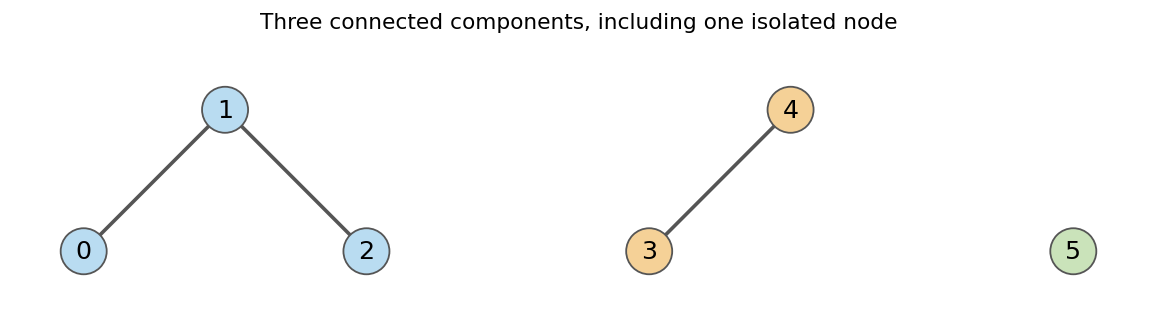

In [4]:
src=np.array([0,1,3],dtype=np.int64);dst=np.array([1,2,4],dtype=np.int64);n=6
expected=np.array([0,0,0,3,3,5])
print('Expected component labels:',expected)
xy=np.array([[0,0],[1,1],[2,0],[4,0],[5,1],[7,0]])
fig,ax=plt.subplots(figsize=(9,2.7))
for s,d in zip(src,dst):ax.plot(xy[[s,d],0],xy[[s,d],1],color='#555',linewidth=2)
ax.scatter(xy[:,0],xy[:,1],s=650,c=['#B9DCF1']*3+['#F5D197']*2+['#CAE3BA'],edgecolors='#555',zorder=3)
for i,(x,y) in enumerate(xy):ax.text(x,y,str(i),ha='center',va='center',zorder=4,fontsize=14)
ax.set_ylim(-.5,1.5);ax.set_xlim(-.5,7.5);ax.axis('off');ax.set_title('Three connected components, including one isolated node')
plt.tight_layout();show()

In [5]:
labels, scans, visits = label_propagation(src, dst, n)
np.testing.assert_array_equal(labels, expected)
print('标签传播结果:', labels)
print('完整扫描次数:', scans, '边访问次数:', visits)

# 逐条边看第一轮发生了什么。
labels = np.arange(n)
for u, v in zip(src, dst):
    before = labels.copy()
    value = min(labels[u], labels[v])
    labels[u] = labels[v] = value
    print(f'边 ({u},{v}): {before} -> {labels}')


标签传播结果: [0 0 0 3 3 5]
完整扫描次数: 2 边访问次数: 6
边 (0,1): [0 1 2 3 4 5] -> [0 0 2 3 4 5]
边 (1,2): [0 0 2 3 4 5] -> [0 0 0 3 4 5]
边 (3,4): [0 0 0 3 4 5] -> [0 0 0 3 3 5]


In [6]:
labels, scans, visits, steps = union_find(src, dst, n)
np.testing.assert_array_equal(labels, expected)
print('并查集结果:', labels)
print('完整扫描次数:', scans, '边访问次数:', visits, '父指针步数:', steps)

# 把合并过程展开，观察代表节点为什么不一定是最小编号。
parent = np.arange(4)
rank = np.zeros(4, dtype=np.uint8)
for u, v in [(2,3), (1,2), (0,1)]:
    x, y = u, v
    while parent[x] != x:
        x = parent[x]
    while parent[y] != y:
        y = parent[y]
    if x != y:
        if rank[x] < rank[y]:
            parent[x] = y
        elif rank[x] > rank[y]:
            parent[y] = x
        else:
            parent[y] = x
            rank[x] += 1
    print(f'处理边 ({u},{v}) 后: parent={parent}, rank={rank}')
reverse_src = np.array([2,1,0], dtype=np.int64)
reverse_dst = np.array([3,2,1], dtype=np.int64)
print('导出最小编号标签:', union_find(reverse_src, reverse_dst, 4)[0])


并查集结果: [0 0 0 3 3 5]
完整扫描次数: 1 边访问次数: 3 父指针步数: 4
处理边 (2,3) 后: parent=[0 1 2 2], rank=[0 0 1 0]
处理边 (1,2) 后: parent=[0 2 2 2], rank=[0 0 1 0]
处理边 (0,1) 后: parent=[2 2 2 2], rank=[0 0 1 0]
导出最小编号标签: [0 0 0 0]


## B. 为什么同一条链换个扫描顺序，工作量就不同？

`0—1—2—3—4—5` 正向扫描时，处理 `(0,1)` 后节点 1 的标签已经是 0，紧接着处理 `(1,2)` 就能把刚得到的 0 传给节点 2。一轮能一路传到末端。

逆向扫描时，先处理 `(4,5)`，再处理 `(3,4)`。节点 4 后来拿到更小标签时，边 `(4,5)` 已处理过了，要等下一轮才能继续传。因此最小标签 0 每轮只能推进一条边。

关键在于上面代码直接修改 `label`，后面的边读取的是**刚更新后的数组**，称为原地或异步标签传播。下面记录每轮的真实标签状态；第 0 行是初始状态，末尾重复的一行是确认收敛。


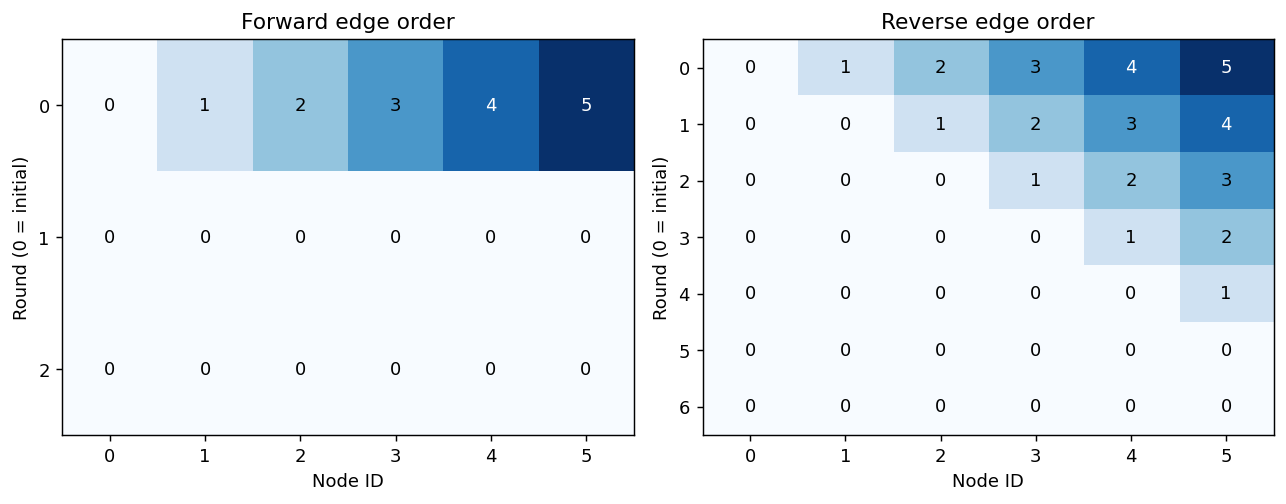

In [7]:
def trace_labels(edges,n):
    labels=np.arange(n);history=[labels.copy()]
    for _ in range(n+1):
        before=labels.copy()
        for u,v in edges:
            value=min(labels[u],labels[v]);labels[u]=value;labels[v]=value
        history.append(labels.copy())
        if np.array_equal(before,labels):break
    return np.array(history)
edges=[(i,i+1) for i in range(5)]
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,es,title in [(axes[0],edges,'Forward edge order'),(axes[1],edges[::-1],'Reverse edge order')]:
    history=trace_labels(es,6)
    ax.imshow(history,cmap='Blues',vmin=0,vmax=5,aspect='auto')
    for row in range(len(history)):
        for col in range(6):ax.text(col,row,str(history[row,col]),ha='center',va='center',color='white' if history[row,col]>3 else 'black')
    ax.set_xticks(range(6));ax.set_yticks(range(len(history)))
    ax.set(xlabel='Node ID',ylabel='Round (0 = initial)',title=title)
plt.tight_layout();show()

## C. 随机捷径图：这是测试数据生成，不是求解步骤

我们先**构造**20 个互不连接的分量，每个分量 3000 个节点：先在组内放一条贯穿全部节点的链，再只在组内添加随机边。最后随机重编号节点、随机打乱边数组。

为什么知道 `(0,3)` 两端已连通？因为生成器先亲手放入了 `(0,1),(1,2),(2,3)`，这条已构造的路径就是依据。对于任意外部输入图，事先判断 0 和 3 是否连通，确实需要遍历或维护连通性；本例没有提供免费的判定方法。

组内加边保持了分量划分，但改变了边数、路径长度和算法工作量。这些额外边称为 shortcut（捷径），可能使标签传播更快收敛。跨组加边会合并分量，生成器没有这么做。

**求解算法没有获得预设分组。** 它们都只拿到同一份最终节点数与边数组，结果再与独立 SciPy 求解比较。该图用于探索“标签传播快速收敛时是否有竞争力”，不代表论文真实图。


### C.1 本地实测：链图与捷径图

保存的结果包括同一条 8192 节点链的三种边顺序，以及一个 60000 节点、20 个互不连通分量的图。后者每个分量有连通骨架和随机捷径，标签容易快速传播。

链是用来暴露算法机制的案例，不代表所有实际图；随机捷径图用于展示相反情况。两种算法都计算到完成，而不是各跑相同轮数就停。链重复 3 次，较大图重复 5 次，取中位数。微秒级差距只作观察，尤其不要据此推广固定倍率。

“扫描边一次”不表示只做 O(m) 的工作：并查集还需要沿父指针查根，本文无路径压缩版本为 O(m log n) 的合并阶段，并另有输出导出成本。标签传播如果扫 k 轮，会访问 k×m 条边。

case                      LP ms      UF ms    LP scans    LP edge visits    UF edge visits
path_forward                   0.019     0.025          2            16,382             8,191
path_reverse                  49.351     0.037       8192        67,100,672             8,191
path_shuffled                 18.439     0.079       4113        33,689,583             8,191
20_components_shortcuts        1.118     5.696          3           899,940           299,980


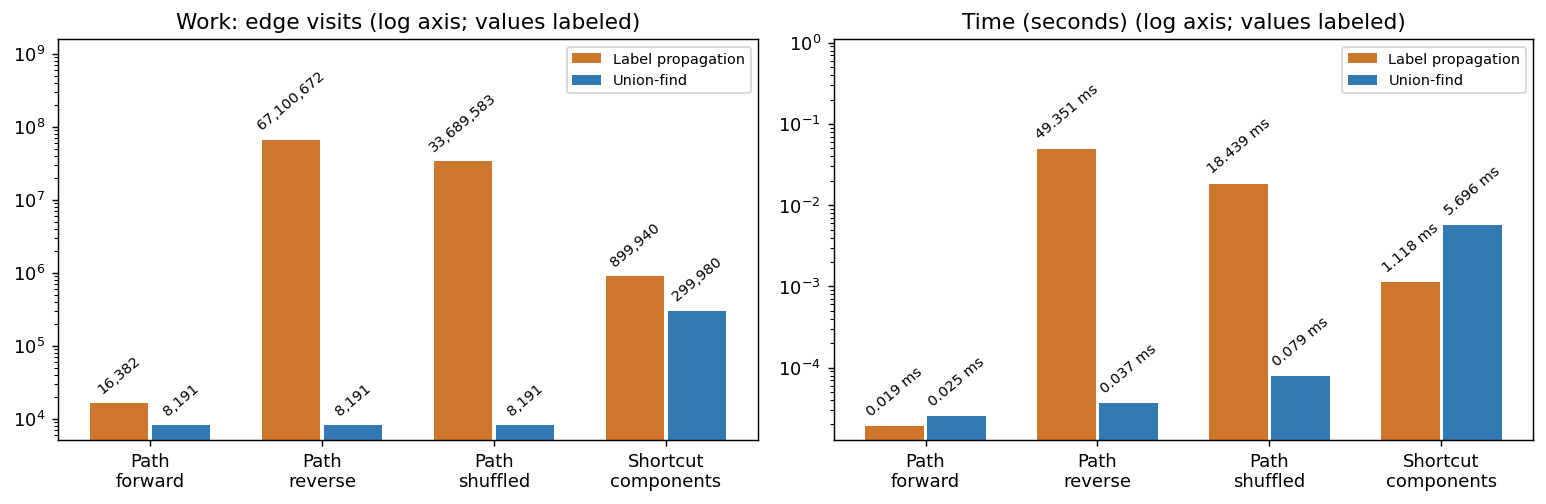

In [8]:
report=json.loads(Path('components_results.json').read_text())
print('case                      LP ms      UF ms    LP scans    LP edge visits    UF edge visits')
for c in report['cases']:
    lp=c['label_propagation'];uf=c['union_find']
    print(f"{c['name']:26s} {lp['median_s']*1000:9.3f} {uf['median_s']*1000:9.3f} {lp['scans']:10d} {lp['edge_visits']:17,d} {uf['edge_visits']:17,d}")
fig,axes=plt.subplots(1,2,figsize=(12,4))
cases=report['cases'];x=np.arange(len(cases))
for ax,field,title in [(axes[0],'edge_visits','Work: edge visits'),(axes[1],'median_s','Time (seconds)')]:
    for offset,key,color,label in [(-.18,'label_propagation','#CE762B','Label propagation'),(.18,'union_find','#3379B4','Union-find')]:
        vals=[c[key][field] for c in cases]
        bars=ax.bar(x+offset,vals,.34,color=color,label=label)
        labels=[f'{v:,}' for v in vals] if field=='edge_visits' else [f'{v*1000:.3f} ms' for v in vals]
        ax.bar_label(bars,labels=labels,rotation=40,padding=4,fontsize=8)
    ax.set_yscale('log');ax.set_ylim(top=ax.get_ylim()[1]*15)
    ax.set_xticks(x,['Path\nforward','Path\nreverse','Path\nshuffled','Shortcut\ncomponents'])
    ax.set_title(title+' (log axis; values labeled)');ax.legend(fontsize=8)
plt.tight_layout();show()

**观察：** 正向链的标签传播只需两次全扫描（一次传播，一次确认），可能比并查集还快；逆向链需要 8192 次扫描。并查集在三种顺序下都只读一遍边，但查根操作的数量和访存模式仍受顺序影响。

在随机捷径图上，原地标签传播仅需 3 轮，实测约 1.12 ms，而并查集约 5.70 ms。**这是应该保留的结果。** 论文用到的图上并查集更快，不意味着所有图都如此。有效基线要在当前任务上验证，不能为了故事好看只选有利样本。

这也解释为什么“并行很多轮”可能比“单线程选更好的算法”慢：如果总工作量增加很多，增加核心只是把这些工作摊开。

## D. 补充 COST 演示：同步并行标签传播

本地对照使用同步标签传播：每轮读取同一份旧标签，各工作线程生成私有输出，再合并并检查收敛。原生 Numba 内核使用 nogil，线程可以并行执行；没有用 Python 逐边循环作性能基线。

它与原文的原地标签传播更新时机不同，但最终划分必须完全相同。同步模型每轮只能使用上一轮的信息，轮数可能更多；这正体现计算模型对工作量的影响。这里 1/2/4 线程均执行到收敛，预热后测量五次，排除线程池创建和 JIT，保留每轮调度、归并及分配。

**基线规则：** 在这个相同任务上，从已测的两个有效串行实现中选择更快的那个，即 `min(串行 LP, 串行 UF)`。这里恰好是串行 LP。还会展示相对 UF 的比值，让你看到选一个较慢基线如何改变门槛结论。

这只是这些本机方案中的基线，不声称已经找到所有可能算法里最快的实现。

### D.1 一个线程处理哪些边？为什么需要新旧两份标签？

同步版本每轮固定一份 `old`，所有线程都只读它。每个线程处理一段边，生成自己的 `result`，初始为 `old.copy()`。读到 `(u,v)` 时：

```python
result[u] = min(result[u], old[v])
result[v] = min(result[v], old[u])
```

`result[u]` 保留当前线程已见过的最小候选值；邻居传来的值始终读取 `old[v]`。即使同一线程刚更新了 v，新值也要下一轮才能传播。每个线程独占输出数组，避免多个线程同时写同一个标签。

下面的 `nogil=True` 允许编译后的内核运行时释放 Python GIL，让多个线程同时执行这个循环。


In [9]:
@njit(nogil=True)
def sync_piece(src, dst, old):
    """Private output; old labels immutable during a round. Safe for threads."""
    result = old.copy()
    for i in range(len(src)):
        u, v = src[i], dst[i]
        result[u] = min(result[u], old[v])
        result[v] = min(result[v], old[u])
    return result

### D.2 主线程如何归并一轮结果？

把边切成 p 段，线程池计算 p 份结果，再对每个节点取所有结果的最小值：`new[v] = min(part_0[v], ..., part_p[v])`。每一份结果都包含旧标签，因此没有某节点相关边的分片不会把它的标签变大。

例如旧标签 `[0,1,2]`，两条边分别交给两个线程：

```text
线程 A 处理 (0,1) → [0,0,2]
线程 B 处理 (1,2) → [0,1,1]
逐位置取最小值   → [0,0,1]
```

第二轮才得到 `[0,0,0]`，第三轮确认停止。相比之下，原地正向扫描第一轮就得到 `[0,0,0]`。

下面把调度与计时也写完整：先预热 JIT；创建线程池；第一次完整运行预热线程；再测量 `repeats` 次取中位数。计时包含标签初始化、每轮任务提交、私有数组分配、归并和停止检查，排除切分准备与线程池创建。

每个线程有一份长度 n 的输出，额外存储约为 O(pn)，每轮归并也要处理 O(pn) 个标签。并行带来的额外工作在代码里可以直接看到。


In [10]:
def parallel_labels(src, dst, n, workers=1, repeats=5):
    """Synchronous full scans: all kernels compiled; no Python-edge-loop baseline."""
    chunks = [(np.ascontiguousarray(s), np.ascontiguousarray(d))
              for s, d in zip(np.array_split(src, workers), np.array_split(dst, workers))]
    sync_piece(chunks[0][0], chunks[0][1], np.arange(n, dtype=np.int64))
    samples=[]
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for rep in range(repeats+1):
            start=time.perf_counter()
            label=np.arange(n, dtype=np.int64)
            scans=0
            while True:
                parts=list(pool.map(lambda edge: sync_piece(edge[0],edge[1],label),chunks))
                new=parts[0]
                for other in parts[1:]: np.minimum(new,other,out=new)
                scans+=1
                done=np.array_equal(label,new)
                label=new
                if done: break
            elapsed=time.perf_counter()-start
            if rep: samples.append(elapsed)
    return label, {'workers':workers,'median_s':float(np.median(samples)),
                   'samples_s':samples,'scans':scans,'edge_visits':scans*len(src)}

In [11]:
chain_src = np.array([0,1], dtype=np.int64)
chain_dst = np.array([1,2], dtype=np.int64)
old_labels = np.arange(3, dtype=np.int64)
part_a = sync_piece(chain_src[:1], chain_dst[:1], old_labels)
part_b = sync_piece(chain_src[1:], chain_dst[1:], old_labels)
print('线程 A:', part_a, '线程 B:', part_b)
print('第一轮合并:', np.minimum(part_a, part_b))
for workers in (1,2,4):
    result, stats = parallel_labels(chain_src, chain_dst, 3, workers=workers, repeats=1)
    np.testing.assert_array_equal(result, [0,0,0])
    print(f'{workers} 线程: labels={result}, scans={stats["scans"]}')
print('这个小例子只验证更新规则；耗时比较读取下方已保存的大图测量。')


线程 A: [0 0 2] 线程 B: [0 1 1]
第一轮合并: [0 0 1]
1 线程: labels=[0 0 0], scans=3
2 线程: labels=[0 0 0], scans=3
4 线程: labels=[0 0 0], scans=3
这个小例子只验证更新规则；耗时比较读取下方已保存的大图测量。


### D.3 为什么标签能够跨越边分片？

线程只分担边，每轮读取同一份完整旧标签，并将所有私有结果按节点取最小值，形成下一轮完整标签。上一轮在一个分片得到的标签，下一轮会被其他分片读到。

因此第 t 轮后，节点知道距离自己不超过 t 条边的最小节点编号。每个有限连通分量内都有有限路径，最小编号最终能传遍分量。前提是每轮覆盖所有边、合并所有结果、直到全局无变化。本实现满足这些条件。

这种按位置取最小值的归并只用于这里的标签传播。并查集的 root/rank 需要维护树结构和一致的合并操作，不能直接套用这个归并规则。本 notebook 没有实现并行并查集。


### D.4 两张图：自身加速比与相对有效串行基线的速度

下图的数据来自 `components_results.json`，不会因修改上面的函数而自动重测。若修改算法并希望更新大图结果，需要同步更新 `paper_algorithms.py`，运行 `benchmark_paper.py` 后重新执行本 notebook。上面的交互例子和下方正确性检查会直接执行本 notebook 定义的函数。

这组结果使用随机捷径图，所有实现拿到同一份随机打乱的边数组。基线不是 forward 链，而是该捷径图上较快的原地串行标签传播。

- **左图**：同步标签传播 1 个工作线程耗时 / p 个工作线程耗时。4 线程为 4.531 / 1.985 ≈ 2.28 倍。
- **右图**：有效串行基线耗时 / 同步标签传播 p 个工作线程耗时。4 线程为 1.118 / 1.985 ≈ 0.56 倍。超过横线 1 才快于基线。

两张图共用同一组并行耗时，只是参照不同。它们演示 COST 的思路，不是论文图 6 的复现。


Chosen competent baseline: serial label propagation 1.118 ms
workers  time ms   self speedup   gain vs UF   gain vs competent baseline  rounds
      1    4.531         1.00x        1.26x                     0.25x       6
      2    2.648         1.71x        2.15x                     0.42x       6
      4    1.985         2.28x        2.87x                     0.56x       6
First measured configuration beating chosen baseline: NOT reached among 1, 2, 4 threads


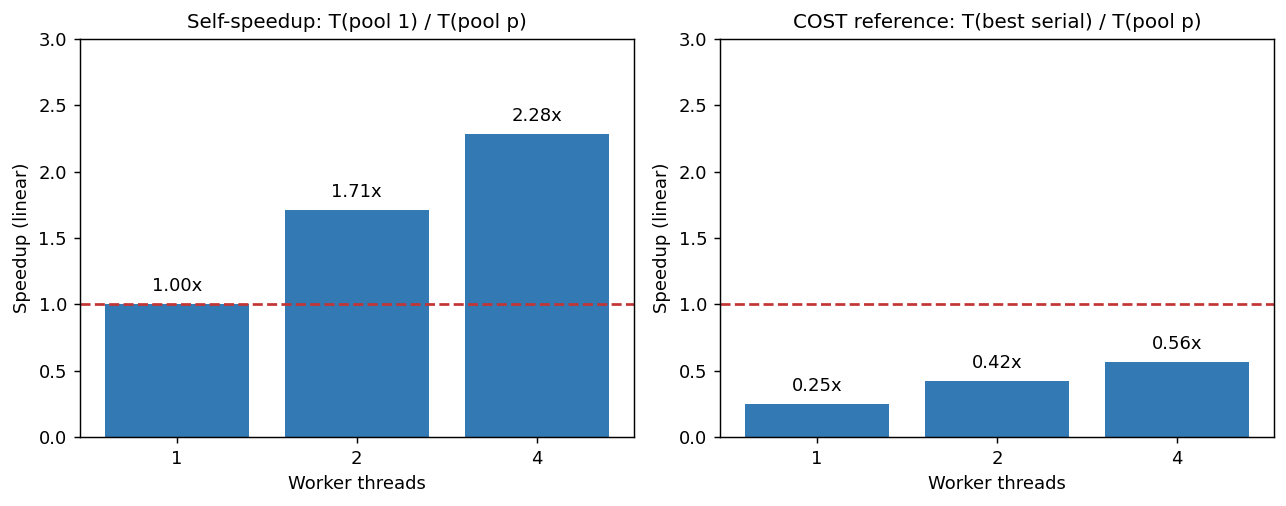

In [12]:
c=next(c for c in report['cases'] if 'parallel' in c)
base=min(c['label_propagation']['median_s'],c['union_find']['median_s'])
base_name='serial label propagation' if c['label_propagation']['median_s']<=c['union_find']['median_s'] else 'serial union-find'
runs=c['parallel'];p=np.array([r['workers'] for r in runs]);t=np.array([r['median_s'] for r in runs]);own=runs[0]['median_s']
print('Chosen competent baseline:',base_name,f'{base*1000:.3f} ms')
print('workers  time ms   self speedup   gain vs UF   gain vs competent baseline  rounds')
for r in runs:
    ts=r['median_s']
    print(f"{r['workers']:7d} {ts*1000:8.3f} {own/ts:12.2f}x {c['union_find']['median_s']/ts:11.2f}x {base/ts:24.2f}x {r['scans']:7d}")
beat=[r['workers'] for r in runs if r['median_s']<base]
print('First measured configuration beating chosen baseline:',min(beat) if beat else 'NOT reached among 1, 2, 4 threads')
fig,axes=plt.subplots(1,2,figsize=(10,4))
x=np.arange(len(p))
for ax,values,title in [(axes[0],own/t,'Self-speedup: T(pool 1) / T(pool p)'),(axes[1],base/t,'COST reference: T(best serial) / T(pool p)')]:
    bars=ax.bar(x,values,color='#3379B4');ax.bar_label(bars,fmt='%.2fx',padding=5)
    ax.axhline(1,color='#C33434',linestyle='--');ax.set_ylim(0,3)
    ax.set_xticks(x,p);ax.set_xlabel('Worker threads');ax.set_ylabel('Speedup (linear)');ax.set_title(title,fontsize=11)
plt.tight_layout();show()

## E. 教学实现的正确性检查

基准脚本已将所有并行结果与 SciPy 的无向连通分量结果逐节点比较，并测试空边集、孤立点、重复边和自环。下面保留一个可以直接运行的独立检查。

SciPy 仅作结果裁判，这里没有把它纳入计时竞争。本 notebook 的串行与并行实现均在上文定义。下面也会验证这些函数；大图计时数据见 `components_results.json`。

In [13]:
def canonical(labels):
    labels=np.asarray(labels)
    minimum=np.full(len(labels),len(labels),dtype=np.int64)
    np.minimum.at(minimum,labels,np.arange(len(labels)))
    return minimum[labels]

for n,s,d in [(5,[0,0,1,3],[1,1,1,3]),(4,[],[]),(1,[0],[0])]:
    s=np.array(s,dtype=np.int64);d=np.array(d,dtype=np.int64)
    graph=csr_matrix((np.ones(len(s)),(s,d)),shape=(n,n))
    _,ref=connected_components(graph,directed=False)
    ref=canonical(ref)
    for fn in (label_propagation,union_find):
        np.testing.assert_array_equal(fn(s,d,n)[0],ref)
    for workers in (1,2,4):
        labels, _ = parallel_labels(s,d,n,workers=workers,repeats=1)
        np.testing.assert_array_equal(labels,ref)
print('Independent SciPy checks passed: isolates, empty edges, duplicate edges, self loops.')
print('Benchmark checks:',report['checks'])

Independent SciPy checks passed: isolates, empty edges, duplicate edges, self loops.
Benchmark checks: scipy reference + empty/isolated/duplicate/self-loop cases passed


## F. 补充实验能说明什么？

**COST 的重点是：资源增加之后，什么时候真正超过一个合理的单线程方案？**

本例的同步标签传播从 1 线程到 4 线程有约 2.28 倍自身加速，但仍慢于有效串行基线，观测到的门槛在 {1,2,4} 中未达到。若只拿较慢的并查集作基线，甚至会认为单 worker 已经“过关”，这会掩盖更有效的替代方案。

在逆向链上，换成并查集却可以大幅减少工作量。两个结果一起说明：算法、数据布局、图结构和计算模型都影响合理基线；不是越并行越好，也不是某一个串行算法永远最好。

原文表 5 是其数据集上的结果：Twitter 图的单线程标签传播 153 s、并查集 15 s；uk 图分别 417 s、30 s。这些历史数字与上面的本机合成图数据分开看。作者通过这些对比要求系统研究认真面对有效替代方案，而不是只报告自己的扩展曲线。

运行：`python run_notebook.py cost_connected_components.ipynb`。重做布局与连通分量基准：`python benchmark_paper.py`（包含 JIT 编译及更大的图，耗时长于只渲染 notebook）。